Feature 0: 0.472553
Feature 1: 0.029193
Feature 2: 2.137658
Feature 3: 29.381059
Feature 4: 8.222601
Feature 5: 8.100183
Feature 6: 1.273822
Feature 7: 0.950682
Feature 8: 3.699989


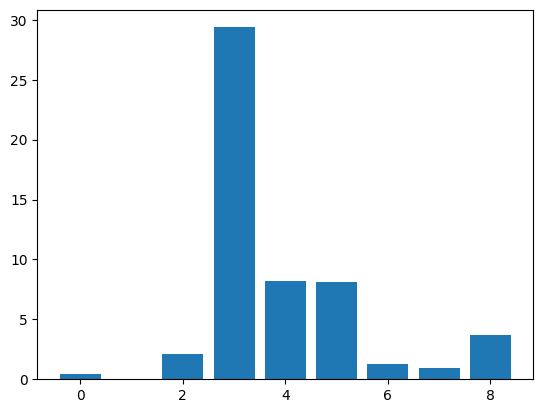

Accuracy: 74.737
Person 1: Breast Cancer
Person 2: No Breast Cancer
Person 3: No Breast Cancer
Person 4: No Breast Cancer
Person 5: No Breast Cancer
Person 6: No Breast Cancer
Person 7: No Breast Cancer
Person 8: No Breast Cancer
Person 9: No Breast Cancer
Person 10: No Breast Cancer
Person 11: No Breast Cancer
Person 12: Breast Cancer
Person 13: No Breast Cancer
Person 14: No Breast Cancer
Person 15: No Breast Cancer
Person 16: No Breast Cancer
Person 17: No Breast Cancer
Person 18: No Breast Cancer
Person 19: No Breast Cancer
Person 20: No Breast Cancer
Person 21: No Breast Cancer
Person 22: No Breast Cancer
Person 23: Breast Cancer
Person 24: Breast Cancer
Person 25: No Breast Cancer
Person 26: Breast Cancer
Person 27: No Breast Cancer
Person 28: No Breast Cancer
Person 29: No Breast Cancer
Person 30: No Breast Cancer
Person 31: No Breast Cancer
Person 32: No Breast Cancer
Person 33: No Breast Cancer
Person 34: No Breast Cancer
Person 35: No Breast Cancer
Person 36: No Breast Cancer

In [1]:
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from matplotlib import pyplot

def load_dataset(filename):
  data = read_csv(filename, header=None)
  dataset = data.values
  X = dataset[:, :-1]
  y = dataset[:,-1]
  X = X.astype(str)
  return X, y

def prepare_inputs(X_train, X_test):
  oe = OrdinalEncoder()
  oe.fit(X_train)
  X_train_enc = oe.transform(X_train)
  X_test_enc = oe.transform(X_test)
  return X_train_enc, X_test_enc

def prepare_targets(y_train, y_test):
  le = LabelEncoder()
  le.fit(y_train)
  y_train_enc = le.transform(y_train)
  y_test_enc = le.transform(y_test)
  return y_train_enc, y_test_enc

def select_features(X_train, y_train, X_test):
  fs = SelectKBest(score_func=chi2, k=4)
  fs.fit(X_train, y_train)
  X_train_fs = fs.transform(X_train)
  X_test_fs = fs.transform(X_test)
  return X_train_fs, X_test_fs, fs

# Main script execution flow
X, y = load_dataset('breast-cancer.csv')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
X_train_enc, X_test_enc = prepare_inputs(X_train, X_test)
y_train_enc, y_test_enc = prepare_targets(y_train, y_test)
X_train_fs, X_test_fs, fs = select_features(X_train_enc, y_train_enc, X_test_enc)

for i in range(len(fs.scores_)):
   print('Feature %d: %f' % (i, fs.scores_[i]))

pyplot.bar([i for i in range(len(fs.scores_))], fs.scores_)
pyplot.show()
model = LogisticRegression(solver='lbfgs')
model.fit(X_train_fs, y_train_enc)
yhat = model.predict(X_test_fs)
accuracy = accuracy_score(y_test_enc, yhat)
print('Accuracy: %.3f' % (accuracy*100))
# Predict on the test data
prediction = model.predict(X_test_fs)

for i in range(len(prediction)):
    if prediction[i] == 0:
        print(f"Person {i+1}: No Breast Cancer")
    else:
        print(f"Person {i+1}: Breast Cancer")

Feature 0: 0.000000
Feature 1: 0.000000
Feature 2: 0.071297
Feature 3: 0.009115
Feature 4: 0.000000
Feature 5: 0.009861
Feature 6: 0.000000
Feature 7: 0.018210
Feature 8: 0.032779


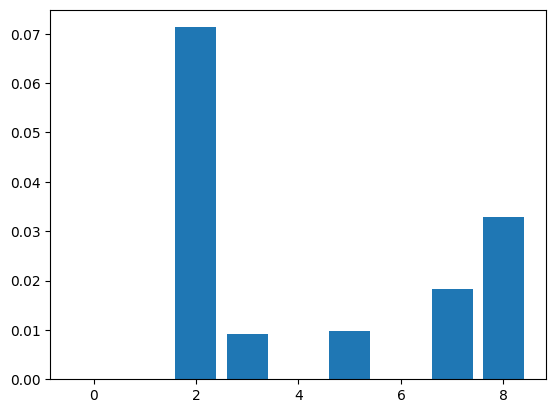

Accuracy: 65.263
Person 1: No Breast Cancer
Person 2: No Breast Cancer
Person 3: No Breast Cancer
Person 4: No Breast Cancer
Person 5: No Breast Cancer
Person 6: No Breast Cancer
Person 7: No Breast Cancer
Person 8: No Breast Cancer
Person 9: No Breast Cancer
Person 10: No Breast Cancer
Person 11: No Breast Cancer
Person 12: No Breast Cancer
Person 13: No Breast Cancer
Person 14: No Breast Cancer
Person 15: No Breast Cancer
Person 16: No Breast Cancer
Person 17: No Breast Cancer
Person 18: No Breast Cancer
Person 19: No Breast Cancer
Person 20: No Breast Cancer
Person 21: No Breast Cancer
Person 22: No Breast Cancer
Person 23: No Breast Cancer
Person 24: No Breast Cancer
Person 25: No Breast Cancer
Person 26: No Breast Cancer
Person 27: No Breast Cancer
Person 28: No Breast Cancer
Person 29: No Breast Cancer
Person 30: No Breast Cancer
Person 31: No Breast Cancer
Person 32: No Breast Cancer
Person 33: No Breast Cancer
Person 34: No Breast Cancer
Person 35: No Breast Cancer
Person 36: N

In [3]:
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from matplotlib import pyplot

def load_dataset(filename):
  data = read_csv(filename, header=None)
  dataset = data.values
  X = dataset[:, :-1]
  y = dataset[:,-1]
  X = X.astype(str)
  return X, y

def prepare_inputs(X_train, X_test):
  oe = OrdinalEncoder()
  oe.fit(X_train)
  X_train_enc = oe.transform(X_train)
  X_test_enc = oe.transform(X_test)
  return X_train_enc, X_test_enc

def prepare_targets(y_train, y_test):
  le = LabelEncoder()
  le.fit(y_train)
  y_train_enc = le.transform(y_train)
  y_test_enc = le.transform(y_test)
  return y_train_enc, y_test_enc

def select_features(X_train, y_train, X_test):
  fs = SelectKBest(score_func=mutual_info_classif,k=4)
  fs.fit(X_train, y_train)
  X_train_fs = fs.transform(X_train)
  X_test_fs = fs.transform(X_test)
  return X_train_fs, X_test_fs, fs

# Main script execution flow
X, y = load_dataset('breast-cancer.csv')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
X_train_enc, X_test_enc = prepare_inputs(X_train, X_test)
y_train_enc, y_test_enc = prepare_targets(y_train, y_test)
X_train_fs, X_test_fs, fs = select_features(X_train_enc, y_train_enc, X_test_enc)

for i in range(len(fs.scores_)):
   print('Feature %d: %f' % (i, fs.scores_[i]))

pyplot.bar([i for i in range(len(fs.scores_))], fs.scores_)
pyplot.show()
model = LogisticRegression(solver='lbfgs')
model.fit(X_train_fs, y_train_enc)
yhat = model.predict(X_test_fs)
accuracy = accuracy_score(y_test_enc, yhat)
print('Accuracy: %.3f' % (accuracy*100))
# Predict on the test data
prediction = model.predict(X_test_fs)

for i in range(len(prediction)):
    if prediction[i] == 0:
        print(f"Person {i+1}: No Breast Cancer")
    else:
        print(f"Person {i+1}: Breast Cancer")